# Week 7 — Deploying a Machine Learning Model

**AVX-DS-W7 | Mall Customer Segmentation Application**

## Project Overview

This project converts the Mall Customer Segmentation model developed in Week 5 into a reusable machine learning pipeline and prepares it for a user-facing application.

The application will accept two customer features:

- Annual Income (k$)
- Spending Score (1–100)

The K-Means model will assign each customer to one of five clusters. The pipeline will include feature scaling and the trained clustering model so that new inputs receive the same preprocessing as the training data.

## Objectives

1. Load and validate the existing customer dataset.
2. Select appropriate features for clustering.
3. evaluate candidate values of K using inertia and silhouette score.
4. Build a StandardScaler and K-Means pipeline.
5. Examine the resulting customer segments.
6. Save the fitted pipeline for use by the Streamlit application.
7. Verify that the saved model can predict clusters for new inputs.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
MODEL_FILENAME = "customer_segmentation_model.pkl"
DATA_FILENAME = "week5_processed_mall_customers.csv"


if not os.path.exists("/content/Mall_Customers.csv"):
    uploaded = files.upload()

    if DATA_FILENAME not in uploaded:
        raise FileNotFoundError(
            f"Please upload the file named {"/content/Mall_Customers.csv"}"
        )


df = pd.read_csv("/content/Mall_Customers.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Data Understanding and Validation

The existing processed dataset contains customer identifiers, demographic information, purchasing capacity, spending behavior, and two scaled columns created during Week 5.

For deployment, the model will use only the original Annual Income and Spending Score columns. CustomerID is an identifier, Genre is not part of the selected clustering features, and Age is retained for describing clusters rather than generating the prediction.

The previously scaled columns are excluded because the new pipeline will fit its own StandardScaler. This avoids applying scaling twice.

Before training, we will inspect column names, data types, missing values, duplicates, and the numerical ranges of the selected features.

In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

required_columns = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

df = df.drop_duplicates().copy()

for column in required_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


if df[required_columns].isnull().any().any():
    raise ValueError(
        "Selected features contain missing or invalid values. "
        "Investigate and handle them before training."
    )

if (df["Annual Income (k$)"] < 0).any():
    raise ValueError("Annual income cannot be negative.")

if not df["Spending Score (1-100)"].between(1, 100).all():
    raise ValueError(
        "Spending Score must be between 1 and 100."
    )

print("\nRows after duplicate removal:", len(df))
print("\nSelected feature statistics:")
display(df[required_columns].describe())

Column names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:
CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Missing values:


,Missing Values
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



Duplicate rows: 0

Rows after duplicate removal: 200

Selected feature statistics:


,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000


## Feature Selection and Pipeline Design

The clustering model will use two numerical features:

- **Annual Income (k$):** represents the customer's purchasing capacity.
- **Spending Score (1–100):** represents the customer's spending behavior.

K-Means relies on distances between observations. StandardScaler standardizes the two features so that differences in their numerical scales do not dominate the distance calculations.

We will place StandardScaler and K-Means inside one scikit-learn Pipeline. This is important for deployment because the fitted scaler and model will be saved together. The application can then transform new customer inputs and assign a cluster using the same fitted preprocessing.

Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
Input matrix shape: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


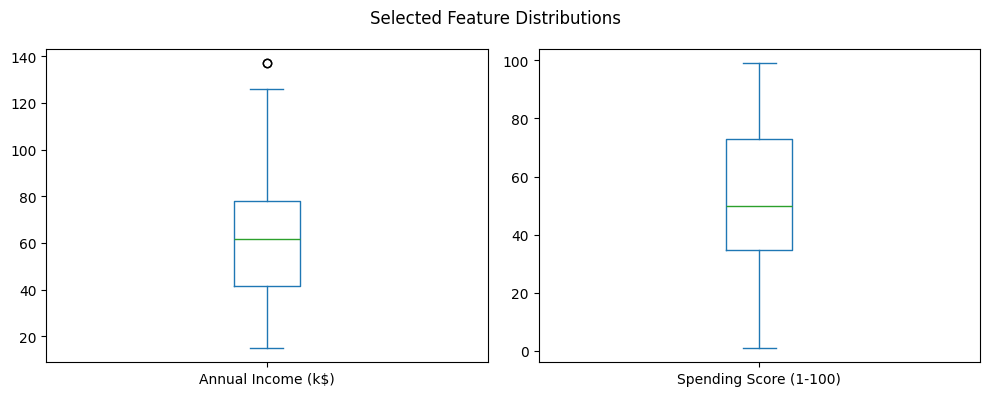

In [3]:
FEATURES = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[FEATURES].copy()

print("Selected features:", FEATURES)
print("Input matrix shape:", X.shape)

display(X.head())

# Inspect the unscaled feature distributions.
X.plot(
    kind="box",
    subplots=True,
    layout=(1, 2),
    figsize=(10, 4),
    title="Selected Feature Distributions"
)

plt.tight_layout()
plt.show()

## Model Evaluation and Selection of K

K-Means requires the number of clusters to be specified in advance. We will evaluate K values from 2 through 6, matching the Week 5 experiment.

Two evaluation measures will be recorded:

- **Inertia:** the sum of squared distances between observations and their assigned cluster centers. Lower inertia indicates tighter clusters, but inertia generally decreases as K increases.
- **Silhouette Score:** measures how well observations fit within their assigned clusters compared with other clusters. A higher score generally indicates better-separated clusters.

For each candidate K, a fresh pipeline will fit StandardScaler and K-Means on the selected raw features. The silhouette score will be calculated on the scaled features and resulting cluster assignments.

The previous Week 5 report selected K=5. We will recompute the results here rather than assume that the new execution produces identical metrics.

,K,Inertia,Silhouette Score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399


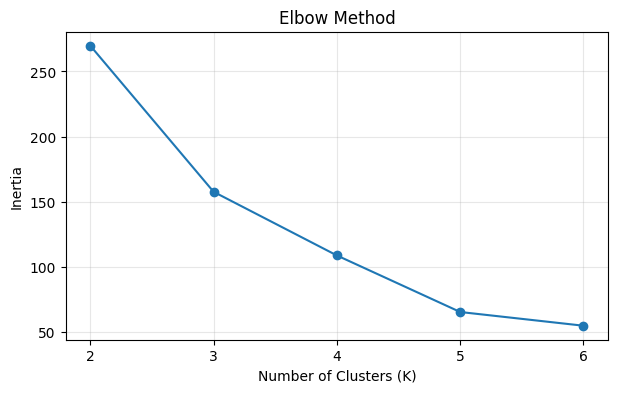

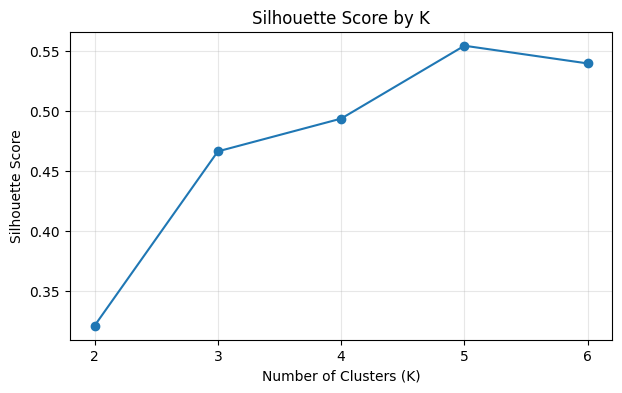

Highest silhouette score observed at K = 5
Silhouette score = 0.5547


In [4]:
evaluation_results = []

for k in range(2, 7):
    candidate_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        ))
    ])

    labels = candidate_pipeline.fit_predict(X)

    X_scaled = candidate_pipeline.named_steps[
        "scaler"
    ].transform(X)

    inertia = candidate_pipeline.named_steps[
        "kmeans"
    ].inertia_

    silhouette = silhouette_score(X_scaled, labels)

    evaluation_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4)
)

# Plot inertia (Elbow Method).
plt.figure(figsize=(7, 4))
plt.plot(
    evaluation_df["K"],
    evaluation_df["Inertia"],
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(2, 7))
plt.grid(True, alpha=0.3)
plt.show()

# Plot silhouette scores.
plt.figure(figsize=(7, 4))
plt.plot(
    evaluation_df["K"],
    evaluation_df["Silhouette Score"],
    marker="o"
)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by K")
plt.xticks(range(2, 7))
plt.grid(True, alpha=0.3)
plt.show()

best_silhouette_row = evaluation_df.loc[
    evaluation_df["Silhouette Score"].idxmax()
]

print(
    "Highest silhouette score observed at K =",
    int(best_silhouette_row["K"])
)
print(
    "Silhouette score =",
    round(best_silhouette_row["Silhouette Score"], 4)
)

## Train the Final Deployment Pipeline

The previous Week 5 analysis selected five clusters, so we will retain K=5 for this deployment version and evaluate the fitted pipeline again.

The pipeline consists of:

1. StandardScaler, fitted on the original two input features.
2. K-Means with five clusters, a fixed random seed, and ten initializations.

The model is fitted once during this notebook execution. The Streamlit application will load the saved pipeline rather than retrain it whenever a user requests a prediction.

In [5]:
FINAL_K = 5

final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=FINAL_K,
        random_state=RANDOM_STATE,
        n_init=10
    ))
])

# Fit the full pipeline once.
final_labels = final_pipeline.fit_predict(X)

# Evaluate the final fitted model.
final_scaled_features = final_pipeline.named_steps[
    "scaler"
].transform(X)

final_inertia = final_pipeline.named_steps[
    "kmeans"
].inertia_

final_silhouette = silhouette_score(
    final_scaled_features,
    final_labels
)

print("Final number of clusters:", FINAL_K)
print("Number of customers used:", len(X))
print("Final inertia:", round(final_inertia, 4))
print("Final silhouette score:", round(final_silhouette, 4))
print("Pipeline steps:", list(final_pipeline.named_steps.keys()))

Final number of clusters: 5
Number of customers used: 200
Final inertia: 65.5684
Final silhouette score: 0.5547
Pipeline steps: ['scaler', 'kmeans']


## Cluster Profiling and Business Interpretation

K-Means cluster IDs are numerical identifiers, not pre-existing customer categories. We will examine the mean annual income, mean spending score, average age where available, and customer count for each cluster.

To make the results easier to understand, we will assign descriptive names based on the relative positions of the fitted cluster centers. These names are interpretations of the data, not ground-truth labels.

The cluster profiles will help explain how a marketing team might use the segments. The recommendations should be treated as exploratory until validated against actual campaign results.

,Cluster,Cluster Name,Customer_Count,Average_Income_k,Average_Spending_Score,Average_Age
0,0,Average-Value Customers,81,55.30,49.52,42.72
1,1,High-Value Active Customers,39,86.54,82.13,32.69
2,2,Budget-Friendly Enthusiasts,22,25.73,79.36,25.27
3,3,High-Income Low-Spending Customers,35,88.20,17.11,41.11
4,4,Low-Engagement Customers,23,26.30,20.91,45.22


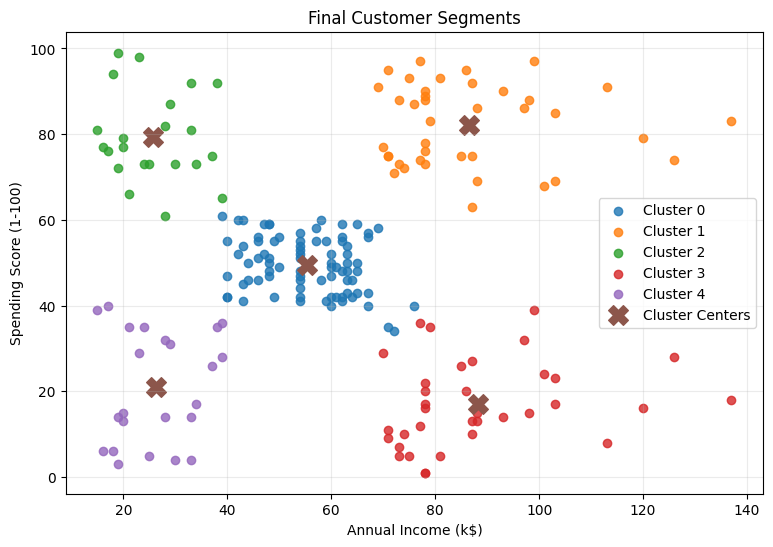

In [6]:
# Keep the original customer data for profiling.
clustered_df = df.copy()
clustered_df["Cluster"] = final_labels

# Get cluster centers back in the original feature units.
kmeans_model = final_pipeline.named_steps["kmeans"]
scaler_model = final_pipeline.named_steps["scaler"]

centers_original = scaler_model.inverse_transform(
    kmeans_model.cluster_centers_
)

centers_df = pd.DataFrame(
    centers_original,
    columns=FEATURES
)
centers_df.index.name = "Cluster"

# Identify the cluster closest to the middle of the cluster centers.
center_medians = centers_df[FEATURES].median()
center_spread = centers_df[FEATURES].std().replace(0, 1)

normalized_center_distance = (
    (centers_df[FEATURES] - center_medians) / center_spread
).pow(2).sum(axis=1)

average_cluster = int(normalized_center_distance.idxmin())

# Create interpretable names from the centers' relative positions.
income_median = centers_df["Annual Income (k$)"].median()
spending_median = centers_df["Spending Score (1-100)"].median()

segment_names = {}

for cluster_id, center in centers_df.iterrows():
    cluster_id = int(cluster_id)

    if cluster_id == average_cluster:
        name = "Average-Value Customers"
    else:
        high_income = center["Annual Income (k$)"] >= income_median
        high_spending = center["Spending Score (1-100)"] >= spending_median

        if high_income and high_spending:
            name = "High-Value Active Customers"
        elif high_income and not high_spending:
            name = "High-Income Low-Spending Customers"
        elif not high_income and high_spending:
            name = "Budget-Friendly Enthusiasts"
        else:
            name = "Low-Engagement Customers"

    segment_names[cluster_id] = name

clustered_df["Cluster Name"] = clustered_df[
    "Cluster"
].map(segment_names)

profile_aggregations = {
    "Customer_Count": ("Cluster", "size"),
    "Average_Income_k": ("Annual Income (k$)", "mean"),
    "Average_Spending_Score": ("Spending Score (1-100)", "mean")
}

if "Age" in clustered_df.columns:
    profile_aggregations["Average_Age"] = ("Age", "mean")

profile = (
    clustered_df.groupby(["Cluster", "Cluster Name"])
    .agg(**profile_aggregations)
    .reset_index()
)

display(profile.round(2))

# Visualize the clusters in the original feature units.
plt.figure(figsize=(9, 6))

for cluster_id in sorted(clustered_df["Cluster"].unique()):
    subset = clustered_df[
        clustered_df["Cluster"] == cluster_id
    ]

    plt.scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=f"Cluster {cluster_id}",
        alpha=0.8
    )

plt.scatter(
    centers_df["Annual Income (k$)"],
    centers_df["Spending Score (1-100)"],
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Final Customer Segments")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

## Prediction Testing

Before saving the model, we will test the fitted pipeline on sample customer inputs. Each input contains annual income and spending score in the same order and units used during training.

Because this is unsupervised clustering, a prediction is a cluster assignment rather than a classification accuracy score. The sample tests verify that the pipeline accepts valid inputs and returns cluster IDs within the fitted range.

The formal application testing will also include invalid and out-of-range inputs.

In [7]:
# Five examples taken from the existing dataset.
sample_inputs = X.head(5).copy()

sample_predictions = final_pipeline.predict(sample_inputs)

sample_results = sample_inputs.copy()
sample_results["Predicted Cluster"] = sample_predictions
sample_results["Cluster Name"] = [
    segment_names[int(cluster)]
    for cluster in sample_predictions
]

display(sample_results)

# Basic prediction checks.
assert len(sample_predictions) == len(sample_inputs)
assert set(sample_predictions).issubset(set(range(FINAL_K)))

print("Sample prediction checks passed.")

,Annual Income (k$),Spending Score (1-100),Predicted Cluster,Cluster Name
0,15,39,4,Low-Engagement Customers
1,15,81,2,Budget-Friendly Enthusiasts
2,16,6,4,Low-Engagement Customers
3,16,77,2,Budget-Friendly Enthusiasts
4,17,40,4,Low-Engagement Customers


Sample prediction checks passed.


## Save the Model for Application Deployment

The final fitted pipeline will be saved as a Joblib artifact. The artifact will contain the fitted StandardScaler and K-Means model, the feature names, cluster descriptions, and the observed training ranges.

Keeping preprocessing and the estimator together prevents the application from accidentally using a different scaler. The model will be loaded once when the application starts, not trained again for every prediction.

After saving, we will reload the artifact and compare its predictions with those from the in-memory pipeline.

In [8]:
# Store the pipeline and metadata together for the future app.
model_bundle = {
    "pipeline": final_pipeline,
    "features": FEATURES,
    "segment_names": segment_names,
    "training_ranges": {
        feature: {
            "min": float(X[feature].min()),
            "max": float(X[feature].max())
        }
        for feature in FEATURES
    },
    "n_clusters": FINAL_K,
    "random_state": RANDOM_STATE
}

joblib.dump(model_bundle, MODEL_FILENAME)

print("Model saved to:", MODEL_FILENAME)
print("File size (bytes):", os.path.getsize(MODEL_FILENAME))

# Reload the saved artifact.
loaded_bundle = joblib.load(MODEL_FILENAME)

loaded_pipeline = loaded_bundle["pipeline"]

# Verify predictions are unchanged after saving and loading.
original_predictions = final_pipeline.predict(sample_inputs)
reloaded_predictions = loaded_pipeline.predict(sample_inputs)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
), "Predictions changed after reloading the model."

print("Reload verification passed.")
print("Features expected by app:", loaded_bundle["features"])
print("Number of clusters:", loaded_bundle["n_clusters"])
print("Cluster descriptions:", loaded_bundle["segment_names"])

Model saved to: customer_segmentation_model.pkl
File size (bytes): 2777
Reload verification passed.
Features expected by app: ['Annual Income (k$)', 'Spending Score (1-100)']
Number of clusters: 5
Cluster descriptions: {0: 'Average-Value Customers', 1: 'High-Value Active Customers', 2: 'Budget-Friendly Enthusiasts', 3: 'High-Income Low-Spending Customers', 4: 'Low-Engagement Customers'}


## Functional Prediction Tests

We will create a record of ten valid customer inputs and the cluster assignments returned by the reloaded model. These tests verify that the saved artifact can process multiple inputs and produce valid cluster IDs.

These are functional tests, not a measurement of predictive accuracy. K-Means is unsupervised, and the dataset does not provide ground-truth customer segment labels against which to calculate classification accuracy.

Input validation for the interactive application will be implemented separately in the Streamlit source code.

In [9]:
# Use ten existing rows as reproducible functional test inputs.
test_inputs = X.head(10).copy().reset_index(drop=True)

test_bundle = joblib.load(MODEL_FILENAME)
test_pipeline = test_bundle["pipeline"]

test_predictions = test_pipeline.predict(test_inputs)

prediction_tests = test_inputs.copy()
prediction_tests.insert(
    0, "Test_ID", range(1, len(test_inputs) + 1)
)
prediction_tests["Predicted_Cluster"] = test_predictions
prediction_tests["Cluster_Name"] = [
    test_bundle["segment_names"][int(cluster)]
    for cluster in test_predictions
]
prediction_tests["Valid_Cluster_ID"] = [
    int(cluster) in range(test_bundle["n_clusters"])
    for cluster in test_predictions
]

assert len(prediction_tests) == 10
assert prediction_tests["Valid_Cluster_ID"].all()

display(prediction_tests)

TEST_FILENAME = "prediction_tests.csv"
prediction_tests.to_csv(TEST_FILENAME, index=False)

print("Number of test inputs:", len(prediction_tests))
print("All cluster IDs valid:", prediction_tests["Valid_Cluster_ID"].all())
print("Test results saved to:", TEST_FILENAME)

,Test_ID,Annual Income (k$),Spending Score (1-100),Predicted_Cluster,Cluster_Name,Valid_Cluster_ID
0,1,15,39,4,Low-Engagement Customers,True
1,2,15,81,2,Budget-Friendly Enthusiasts,True
2,3,16,6,4,Low-Engagement Customers,True
3,4,16,77,2,Budget-Friendly Enthusiasts,True
4,5,17,40,4,Low-Engagement Customers,True
5,6,17,76,2,Budget-Friendly Enthusiasts,True
6,7,18,6,4,Low-Engagement Customers,True
7,8,18,94,2,Budget-Friendly Enthusiasts,True
8,9,19,3,4,Low-Engagement Customers,True
9,10,19,72,2,Budget-Friendly Enthusiasts,True


Number of test inputs: 10
All cluster IDs valid: True
Test results saved to: prediction_tests.csv


## Deployment Artifacts

The trained pipeline and prediction test results are saved as separate files. These files will be used in the next stage to build and verify the Streamlit application.

The saved model must be kept alongside the application source code, and its dependencies must be documented so that the application can be reproduced on another computer.

In [10]:
# Download the saved pipeline.
files.download(MODEL_FILENAME)

# Download the functional test results.
files.download(TEST_FILENAME)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>